In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ensembles import *
from functions.repeated_cv import *
from functions.postproc import *

from sklearn import set_config
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import RandomizedSearchCV
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import make_scorer
from sklearn.preprocessing import OneHotEncoder
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold
from sksurv.metrics import integrated_brier_score
from sksurv.metrics import concordance_index_ipcw
from sksurv.nonparametric import kaplan_meier_estimator
from sklearn.inspection import permutation_importance

from sksurv.ensemble import RandomSurvivalForest
from sksurv.metrics import concordance_index_censored
from sksurv.util import Surv
from sksurv.ensemble import ComponentwiseGradientBoostingSurvivalAnalysis
from sksurv.linear_model import CoxnetSurvivalAnalysis

import time
set_config(display="text")  # displays text representation of estimators

In [2]:
dataset = pd.read_csv("../../data/data_cox/data.csv")

diagnosis_variables = []

with open("../../data/data_cox/diagnosis.txt", "r") as file:
    for line in file:
        diagnosis_variables.append(line.strip())

treatment_variables = []
with open("../../data/data_cox/treatment.txt", "r") as file:
    for line in file:
        treatment_variables.append(line.strip())

survival_dataset = dataset.drop('Unnamed: 0', axis=1)

feature_columns = treatment_variables + diagnosis_variables

continuous_features =  ['Age', 'Ki67 positive cells (%) at CB', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered']
continuous_features = [col for col in continuous_features if col in feature_columns]

In [3]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
groups = survival_dataset['PERSON_ID']

# Stratification settings (toggle this flag)
n_splits = 5
use_time_strata = False  # Set to False to use outcome-only stratification
max_time_bins = 3

event_col = survival_dataset['Regional LN recurrence'].astype(int)
time_col = survival_dataset['Survival days']

strata_labels = None
chosen_bins = None
recurrence_mask = (event_col == 1)

if use_time_strata:
    # Outcome-Length stratification: time bins only for recurrence cases
    for n_bins in range(max_time_bins, 1, -1):
        try:
            # Build quantile bins using only recurrence cases
            recurrence_time_bins = pd.qcut(
                time_col.loc[recurrence_mask], q=n_bins, labels=False, duplicates='drop'
            )

            # Non-recurrence rows share one label; recurrence rows get time-bin labels
            candidate_labels = pd.Series('0_noevent', index=survival_dataset.index, dtype='object')
            candidate_labels.loc[recurrence_mask] = (
                '1_' + recurrence_time_bins.astype(int).astype(str)
            ).values

            # Every stratum must have at least n_splits samples for stable balancing
            if candidate_labels.value_counts().min() >= n_splits:
                strata_labels = candidate_labels
                chosen_bins = int(recurrence_time_bins.nunique())
                break
        except ValueError:
            continue

if strata_labels is None:
    # Explicit switch OR sparse recurrence-time bins -> outcome-only stratification
    strata_labels = event_col.astype(str)
    if use_time_strata:
        print('Fallback: using outcome-only stratification (recurrence time bins too sparse).')
    else:
        print('Using outcome-only stratification (time-based stratification disabled).')
else:
    print(f'Using recurrence-only time stratification with {chosen_bins} time bins.')

# sgkf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=12)
# cv = sgkf.split(X=data_x, y=strata_labels)

# train_index, test_index = next(cv)

manual_splits, manual_fold_summary = build_manual_stratified_group_folds(
    event_series=event_col,
    group_series=groups,
    strata_series=strata_labels,
    keep_groups_for_events=False,
    n_splits=n_splits,
    random_state=302
)

print('Manual grouped fold balancing summary:')
print(manual_fold_summary.to_string(index=False))

# Keep variable name for compatibility in later cells
cv = manual_splits
train_index, test_index = manual_splits[0]

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

print(f'Train size: {len(train_index)}, Test size: {len(test_index)}')

Using outcome-only stratification (time-based stratification disabled).
Manual grouped fold balancing summary:
 fold  target_events  assigned_events  target_samples  assigned_samples  valid_event_rate  target_event_strata_1  assigned_event_strata_1
    1              6                6             646               646          0.009288                      6                        6
    2              6                6             646               646          0.009288                      6                        6
    3              5                5             646               646          0.007740                      5                        5
    4              5                5             645               645          0.007752                      5                        5
    5              5                5             645               645          0.007752                      5                        5
Train size: 2582, Test size: 646


In [4]:
from sklearn.preprocessing import MinMaxScaler

# Define time points for calibration analysis (1, 2, 3, 4, 5 years)
time_points = [365, 730, 1095, 1460, 1825]  # in days

# # Use the best model parameters found earlier
# best_params_for_calibration = {
#     'alphas': [0.000464159],
#     'l1_ratio': 1.0,
#     'fit_baseline_model': True
#     }
# Use the best model parameters found earlier
best_params_for_calibration = {
    'alphas': [0.000621017],
    'l1_ratio': 1.0,
    'fit_baseline_model': True
    }

n_controls=["Full"]

# predictions_df = pd.read_csv("cox_calibration_predictions.csv")

scaler = MinMaxScaler()
x_train_scaled = x_train.copy()

cols_to_scale = [col for col in continuous_features if col in x_train_scaled.columns]
x_train_scaled[cols_to_scale] = scaler.fit_transform(x_train_scaled[cols_to_scale])

x_test_scaled = x_test.copy()
x_test_scaled[cols_to_scale] = scaler.transform(x_test_scaled[cols_to_scale])

cox_model = CoxnetSurvivalAnalysis(**best_params_for_calibration)
cox_model.fit(x_train_scaled, y_train)

# Compute Harrell's c-index on train and test sets
train_risk = cox_model.predict(x_train_scaled)
c_index_train = concordance_index_censored(
    y_train["event"], y_train["time"], train_risk
)[0]

test_risk = cox_model.predict(x_test_scaled)
c_index_test = concordance_index_censored(
    y_test["event"], y_test["time"], test_risk
)[0]

print(f"Train c-index: {c_index_train:.4f}")
print(f"Test c-index: {c_index_test:.4f}")

# ---- Final coefficients: refit on the whole dataset (train + test) ----
# Same tuned hyperparameters as cox_model above, but both the scaler and the model
# are refit on every patient so the reported coefficients aren't limited to the
# training split. The train/test c-index above still come from the train-only
# cox_model, since those numbers describe out-of-sample generalization.
full_scaler = MinMaxScaler()
x_full_scaled = data_x.copy()
x_full_scaled[cols_to_scale] = full_scaler.fit_transform(x_full_scaled[cols_to_scale])

cox_model_full = CoxnetSurvivalAnalysis(**best_params_for_calibration)
cox_model_full.fit(x_full_scaled, data_y)

# Build coefficient table
coef_array = cox_model_full.coef_
if coef_array.ndim == 1:
    coef_values = coef_array
else:
    # best_params_for_calibration has one alpha, so take first column
    coef_values = coef_array[:, 0]

coef_df = pd.DataFrame({
    "feature": x_full_scaled.columns,
    "coefficient": coef_values
})
coef_df["abs_coefficient"] = coef_df["coefficient"].abs()
coef_df = coef_df.sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

# Optional: non-zero coefficients only
nonzero_coef_df = coef_df[coef_df["coefficient"] != 0].reset_index(drop=True)
size = len(nonzero_coef_df)

print("All coefficients (sorted by absolute value):")
print(coef_df.to_string(index=False))

print(f"\nNon-zero coefficients ({size}):")
print(nonzero_coef_df.to_string(index=False))

Train c-index: 0.9333
Test c-index: 0.9024
All coefficients (sorted by absolute value):
                                                  feature  coefficient  abs_coefficient
                          Oestrogen receptor status at CB    -2.138313         2.138313
         Neoadjuvant (Only) therapy with biological drugs     1.712996         1.712996
                                        Isotype at CB_4.0     0.990283         0.990283
                     Radiotherapy on supraclavicular area     0.737387         0.737387
                  Adjuvant therapy using biological drugs    -0.550056         0.550056
                                  Total administered dose    -0.521576         0.521576
                                          Grade at CB_3.0     0.504638         0.504638
               Treatment in association with chemotherapy     0.180708         0.180708
                              Side location of the lesion    -0.178310         0.178310
                                

## Graphs

In [9]:
# ---- Default CoxnetSurvivalAnalysis (no tuned hyperparameters), whole training set ----
# Same scaled features as the tuned model above (x_train_scaled / y_train), but using the
# class's own defaults (a full 100-alpha regularization path, l1_ratio=0.5) instead of
# best_params_for_calibration. predict() with no alpha uses the last (smallest, least-
# regularized) alpha on that path. Kept separate from cox_model so the calibration and
# coefficient results above stay untouched -- this is only for the C-index evolution below.
default_cox_model = CoxnetSurvivalAnalysis()
default_cox_model.fit(x_train_scaled, y_train)

default_train_risk = default_cox_model.predict(x_train_scaled)
default_c_index_train = concordance_index_censored(
    y_train["event"], y_train["time"], default_train_risk
)[0]
print(f"Default Coxnet train c-index: {default_c_index_train:.4f}")

Default Coxnet train c-index: 0.9462


### IPCW (Uno's) C-index

Uno, H., Cai, T., Pencina, M. J., D'Agostino, R. B., & Wei, L. J. (2011). On the C-statistics for evaluating overall adequacy of risk prediction procedures with censored survival data. *Statistics in Medicine*, 30(10), 1105–1117.


In [10]:
# ---- IPCW (Uno's) C-index across the whole follow-up horizon, whole training set, no CV ----
# Uses default_cox_model (defaults, not the tuned hyperparameters) from the cell above, so
# its risk score is a fixed, time-invariant ranking. `dataset` (loaded in the first cell)
# is never touched by the 5-year capping -- only `survival_dataset` is -- so it still
# holds each patient's true, uncapped event/time.
y_train_uncapped = Surv.from_arrays(
    event=dataset['Regional LN recurrence'].iloc[train_index],
    time=dataset['Survival days'].iloc[train_index]
)

max_horizon_years = 14
ipcw_rows = []

for year in range(1, max_horizon_years + 1):
    tau = year * 365
    n_at_risk = int((y_train_uncapped['time'] >= tau).sum())
    try:
        c_ipcw, concordant, discordant, tied_risk, tied_time = concordance_index_ipcw(
            y_train_uncapped, y_train_uncapped, default_train_risk, tau=tau
        )
        n_pairs = concordant + discordant + tied_risk
    except ValueError as err:
        c_ipcw, n_pairs = np.nan, np.nan
        print(f"year {year:2d} (tau={tau}d): could not compute IPCW C-index ({err})")

    ipcw_rows.append({
        'year': year, 'tau_days': tau,
        'c_index_ipcw': c_ipcw, 'n_at_risk': n_at_risk, 'n_comparable_pairs': n_pairs
    })

ipcw_evolution_df = pd.DataFrame(ipcw_rows)
print(ipcw_evolution_df.to_string(index=False))

 year  tau_days  c_index_ipcw  n_at_risk  n_comparable_pairs
    1       365      0.975845       2441               36771
    2       730      0.986604       1893               36771
    3      1095      0.990461       1623               36771
    4      1460      0.940115       1162               36771
    5      1825      0.900759        914               36771
    6      2190      0.857316        321               36771
    7      2555      0.836826        161               36771
    8      2920      0.817334         99               36771
    9      3285      0.817334         60               36771
   10      3650      0.817334         36               36771
   11      4015      0.817334          8               36771
   12      4380      0.275951          6               36771
   13      4745      0.275951          6               36771
   14      5110      0.275951          5               36771


In [11]:
# ---- Harrell's (standard) C-index across the same horizons, whole training set, no CV ----
# Uses default_train_risk from the default CoxnetSurvivalAnalysis fit above. Harrell's
# C-index has no tau parameter, so the standard way to evaluate it at a fixed horizon is
# to administratively censor the labels at that horizon first (event only if it happened
# by tau, time capped at tau), then run the ordinary concordance index on that.
harrell_rows = []

for year in range(1, max_horizon_years + 1):
    tau = year * 365
    time_h = np.minimum(y_train_uncapped['time'], tau)
    event_h = y_train_uncapped['event'] & (y_train_uncapped['time'] <= tau)
    n_at_risk = int((y_train_uncapped['time'] >= tau).sum())

    c_harrell = concordance_index_censored(event_h, time_h, default_train_risk)[0]

    harrell_rows.append({'year': year, 'tau_days': tau, 'c_index_harrell': c_harrell, 'n_at_risk': n_at_risk})

harrell_evolution_df = pd.DataFrame(harrell_rows)
print(harrell_evolution_df.to_string(index=False))

 year  tau_days  c_index_harrell  n_at_risk
    1       365         0.976256       2441
    2       730         0.985692       1893
    3      1095         0.988477       1623
    4      1460         0.963517       1162
    5      1825         0.946222        914
    6      2190         0.931508        321
    7      2555         0.929811        161
    8      2920         0.929285         99
    9      3285         0.929285         60
   10      3650         0.929285         36
   11      4015         0.929285          8
   12      4380         0.929135          6
   13      4745         0.929135          6
   14      5110         0.929135          5


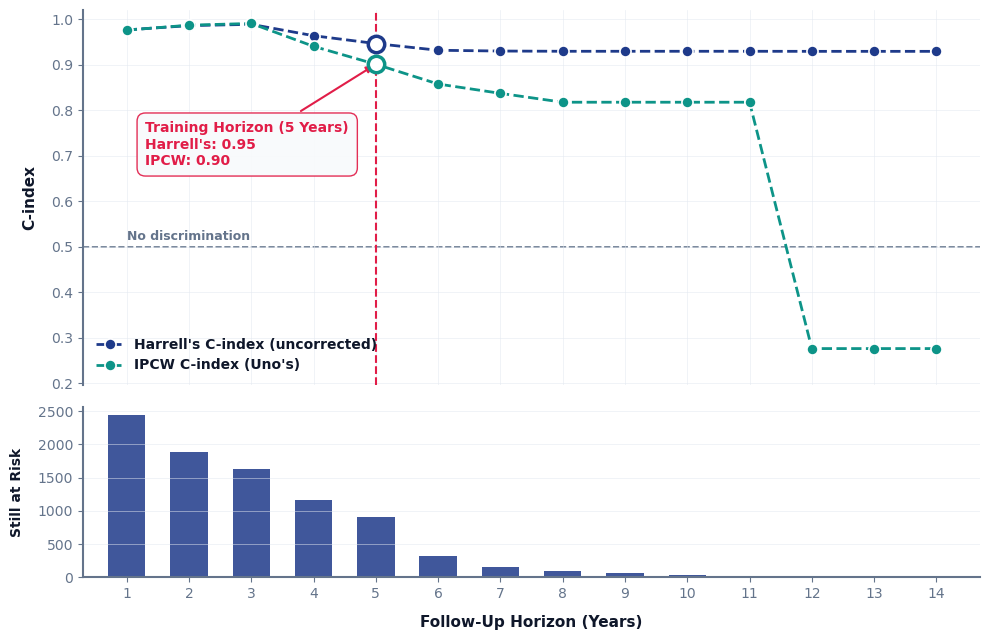

In [13]:
# ---- Combined C-index evolution: IPCW (Uno's) vs. Harrell's, thesis-ready ----
# Same visual system as clinical_censoring_plot_transparent: both series share one
# 0-1 C-index scale (no dual axis -- they're the same kind of measure), points per
# year joined by a dashed guide line (these are 14 separate point estimates, not a
# continuous function), plus the shared at-risk panel underneath.
NAVY = '#1E3A8A'
TEAL = '#0D9488'
CRIMSON = '#E11D48'
SLATE = '#0F172A'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'
BOX_BG = '#F8FAFC'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'axes.edgecolor': MUTED,
})

fig, (ax_c, ax_n) = plt.subplots(
    2, 1, figsize=(10, 6.5), sharex=True,
    gridspec_kw={'height_ratios': [2.2, 1]}
)
ax_c.set_facecolor('none')
ax_n.set_facecolor('none')

ax_c.axhline(0.5, color=MUTED, linestyle='--', linewidth=1.2, zorder=1)
ax_c.text(1, 0.515, 'No discrimination', color=MUTED, fontsize=9, fontweight='bold')

ax_c.plot(harrell_evolution_df['year'], harrell_evolution_df['c_index_harrell'],
          color=NAVY, linewidth=2, linestyle='--', marker='o', markersize=8,
          markeredgecolor='white', markeredgewidth=1.2, zorder=3,
          label="Harrell's C-index (uncorrected)")
ax_c.plot(ipcw_evolution_df['year'], ipcw_evolution_df['c_index_ipcw'],
          color=TEAL, linewidth=2, linestyle='--', marker='o', markersize=8,
          markeredgecolor='white', markeredgewidth=1.2, zorder=3,
          label="IPCW C-index (Uno's)")

# 5-year training-horizon marker + annotation
harrell_5y = harrell_evolution_df.loc[harrell_evolution_df['year'] == 5, 'c_index_harrell'].iloc[0]
ipcw_5y = ipcw_evolution_df.loc[ipcw_evolution_df['year'] == 5, 'c_index_ipcw'].iloc[0]
ax_c.axvline(5, color=CRIMSON, linestyle='--', linewidth=1.5, zorder=2)
ax_c.scatter([5], [harrell_5y], color='white', edgecolor=NAVY, s=140, linewidth=2.5, zorder=5)
ax_c.scatter([5], [ipcw_5y], color='white', edgecolor=TEAL, s=140, linewidth=2.5, zorder=5)

bbox_props = dict(boxstyle="round,pad=0.6", fc=BOX_BG, ec=CRIMSON, alpha=0.92, lw=1)
ax_c.annotate(
    f"Training Horizon (5 Years)\nHarrell's: {harrell_5y:.2f}\nIPCW: {ipcw_5y:.2f}",
    xy=(5, ipcw_5y),
    xytext=(1.3, 0.68),
    arrowprops=dict(arrowstyle="-|>", color=CRIMSON, lw=1.5),
    fontsize=10, fontweight='bold', color=CRIMSON,
    bbox=bbox_props
)

ax_c.set_ylabel("C-index", fontsize=11, fontweight='bold', labelpad=10)
c_min = float(min(ipcw_evolution_df['c_index_ipcw'].min(), harrell_evolution_df['c_index_harrell'].min()))
ax_c.set_ylim(max(0.0, min(0.45, c_min - 0.08)), 1.02)
ax_c.grid(color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax_c.spines['top'].set_visible(False)
ax_c.spines['right'].set_visible(False)
ax_c.spines['left'].set_linewidth(1.5)
ax_c.spines['bottom'].set_visible(False)
ax_c.tick_params(axis='x', length=0)

leg = ax_c.legend(loc='lower left', frameon=False)
for text in leg.get_texts():
    text.set_fontweight('bold')

# Bottom: patients still at risk (shared by both curves -- same population, same horizons)
ax_n.bar(ipcw_evolution_df['year'], ipcw_evolution_df['n_at_risk'],
         color=NAVY, alpha=0.85, width=0.6)
ax_n.set_xlabel('Follow-Up Horizon (Years)', fontsize=11, fontweight='bold', labelpad=10)
ax_n.set_ylabel('Still at Risk', fontsize=10, fontweight='bold', labelpad=10)
ax_n.set_xticks(range(1, max_horizon_years + 1))
ax_n.set_xlim(0.3, max_horizon_years + 0.7)
ax_n.grid(color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7, axis='y')
ax_n.spines['top'].set_visible(False)
ax_n.spines['right'].set_visible(False)
ax_n.spines['left'].set_linewidth(1.5)
ax_n.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()
plt.savefig('cindex_evolution_transparent.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('cindex_evolution_transparent.pdf', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

### Time-dependent AUC(t): training vs. held-out test

Uno's cumulative/dynamic AUC (`sksurv.metrics.cumulative_dynamic_auc`), IPCW-weighted for censoring, at every half-year horizon from 0.5 to 5.0y -- using the risk score from the *tuned* Coxnet model (`cox_model`, fit on `x_train_scaled`/`y_train` above, not the untuned `default_cox_model` used for the C-index evolution plot). The training curve is evaluated in-sample (optimistic, like Harrell's C-index above); the held-out test fold (`x_test_scaled`/`y_test`, fold 0 of the grouped 5-fold split, never seen during fitting) gives a genuine out-of-sample estimate at the same horizons. The censoring distribution needed for the IPCW weights is estimated from `y_train` for both curves, since it is the larger sample. This section calls `cumulative_dynamic_auc` directly per horizon, so the horizon list itself is fully dynamic (see the bootstrap section below for the one part that isn't).


In [16]:
NAVY = '#1E3A8A'
TEAL = '#0D9488'
CRIMSON = '#E11D48'
SLATE = '#0F172A'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'
BOX_BG = '#F8FAFC'

In [14]:
# ---- Time-dependent AUC(t): training (in-sample) vs. held-out test, tuned Cox model ----
# Reuses cox_model / train_risk / test_risk / x_train_scaled / x_test_scaled / y_train / y_test
# from the calibration cell above. Horizons are every 0.5y from 0.5 to 5.0y --
# cumulative_dynamic_auc is called directly per horizon (no lookup table), so this loop is
# dynamic to any horizon list you pass it, unlike the bootstrap section below.
from sksurv.metrics import cumulative_dynamic_auc

auc_horizons_years = np.arange(0.5, 5.0 + 1e-9, 0.5)
auc_horizons_days = auc_horizons_years * 365

max_auc_time = min(y_train['time'].max(), y_test['time'].max())

auc_rows = []
for tau in auc_horizons_days:
    year = tau / 365
    n_at_risk_test = int((y_test['time'] >= tau).sum())
    train_auc_t, test_auc_t = np.nan, np.nan
    if tau <= max_auc_time:
        try:
            train_auc_t, _ = cumulative_dynamic_auc(y_train, y_train, train_risk, [tau])
            test_auc_t, _ = cumulative_dynamic_auc(y_train, y_test, test_risk, [tau])
            train_auc_t, test_auc_t = train_auc_t[0], test_auc_t[0]
        except ValueError as err:
            print(f'year {year:.1f} (tau={tau:.0f}d): could not compute AUC(t) ({err})')
    auc_rows.append({
        'year': year, 'tau_days': tau,
        'auc_train': train_auc_t, 'auc_test': test_auc_t,
        'n_at_risk_test': n_at_risk_test
    })

auc_evolution_df = pd.DataFrame(auc_rows)
print(auc_evolution_df.to_string(index=False))


 year  tau_days  auc_train  auc_test  n_at_risk_test
  1.0       365   0.954314  0.972430             601
  2.0       730   0.976635  0.969323             474
  3.0      1095   0.982463  0.878665             405
  4.0      1460   0.935582  0.876382             290
  5.0      1825   0.845930  0.874386             241


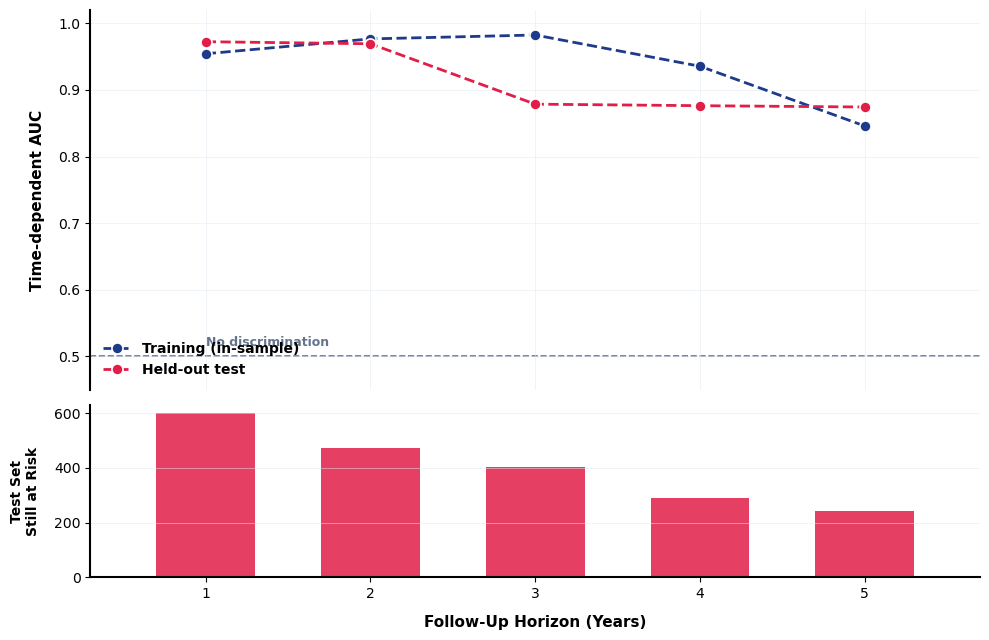

In [17]:
# ---- Plot: time-dependent AUC, train vs. test -- same visual system as cindex_evolution ----
fig, (ax_a, ax_n) = plt.subplots(
    2, 1, figsize=(10, 6.5), sharex=True,
    gridspec_kw={'height_ratios': [2.2, 1]}
)
ax_a.set_facecolor('none')
ax_n.set_facecolor('none')

ax_a.axhline(0.5, color=MUTED, linestyle='--', linewidth=1.2, zorder=1)
ax_a.text(0.5, 0.515, 'No discrimination', color=MUTED, fontsize=9, fontweight='bold')

ax_a.plot(auc_evolution_df['year'], auc_evolution_df['auc_train'],
          color=NAVY, linewidth=2, linestyle='--', marker='o', markersize=6,
          markeredgecolor='white', markeredgewidth=1.2, zorder=3,
          label='Training (in-sample)')
ax_a.plot(auc_evolution_df['year'], auc_evolution_df['auc_test'],
          color=CRIMSON, linewidth=2, linestyle='--', marker='o', markersize=6,
          markeredgecolor='white', markeredgewidth=1.2, zorder=3,
          label='Held-out test')

ax_a.set_ylabel('Time-dependent AUC', fontsize=11, fontweight='bold', labelpad=10)
auc_min = float(np.nanmin(auc_evolution_df[['auc_train', 'auc_test']].values))
ax_a.set_ylim(max(0.0, min(0.45, auc_min - 0.08)), 1.02)
ax_a.grid(color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax_a.spines['top'].set_visible(False)
ax_a.spines['right'].set_visible(False)
ax_a.spines['left'].set_linewidth(1.5)
ax_a.spines['bottom'].set_visible(False)
ax_a.tick_params(axis='x', length=0)

leg = ax_a.legend(loc='lower left', frameon=False)
for text in leg.get_texts():
    text.set_fontweight('bold')

ax_n.bar(auc_evolution_df['year'], auc_evolution_df['n_at_risk_test'],
         color=CRIMSON, alpha=0.85, width=0.35)
ax_n.set_xlabel('Follow-Up Horizon (Years)', fontsize=11, fontweight='bold', labelpad=10)
ax_n.set_ylabel('Test Set\nStill at Risk', fontsize=10, fontweight='bold', labelpad=10)
_auc_year_ticks = auc_evolution_df['year'].to_numpy()
ax_n.set_xticks(_auc_year_ticks)
ax_n.set_xticklabels([f'{y:g}' for y in _auc_year_ticks], fontsize=8)
ax_n.set_xlim(_auc_year_ticks.min() - 0.3, _auc_year_ticks.max() + 0.3)
ax_n.grid(color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7, axis='y')
ax_n.spines['top'].set_visible(False)
ax_n.spines['right'].set_visible(False)
ax_n.spines['left'].set_linewidth(1.5)
ax_n.spines['bottom'].set_linewidth(1.5)

plt.tight_layout()
plt.savefig('auc_evolution_train_test_transparent.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('auc_evolution_train_test_transparent.pdf', dpi=300, transparent=True, bbox_inches='tight')
plt.show()


## Grouping logs

In [9]:
# Event / non-event counts for each fold (train and validation)

event_series = survival_dataset['Regional LN recurrence'].astype(int).reset_index(drop=True)

if 'manual_splits' in globals():
    fold_iterator = manual_splits
else:
    fold_iterator = list(sgkf.split(X=data_x, y=strata_labels, groups=groups))

fold_rows = []
for fold_id, (tr_idx, va_idx) in enumerate(fold_iterator, start=1):
    tr_events = int(event_series.iloc[tr_idx].sum())
    tr_non_events = int(len(tr_idx) - tr_events)

    va_events = int(event_series.iloc[va_idx].sum())
    va_non_events = int(len(va_idx) - va_events)

    fold_rows.append({
        "fold": fold_id,
        "train_n": len(tr_idx),
        "train_events": tr_events,
        "train_non_events": tr_non_events,
        "train_event_rate": round(tr_events / len(tr_idx), 4) if len(tr_idx) > 0 else np.nan,
        "valid_n": len(va_idx),
        "valid_events": va_events,
        "valid_non_events": va_non_events,
        "valid_event_rate": round(va_events / len(va_idx), 4) if len(va_idx) > 0 else np.nan
    })

fold_event_counts_df = pd.DataFrame(fold_rows)
print(fold_event_counts_df.to_string(index=False))

 fold  train_n  train_events  train_non_events  train_event_rate  valid_n  valid_events  valid_non_events  valid_event_rate
    1     2582            21              2561            0.0081      646             6               640            0.0093
    2     2582            21              2561            0.0081      646             6               640            0.0093
    3     2582            22              2560            0.0085      646             5               641            0.0077
    4     2583            22              2561            0.0085      645             5               640            0.0078
    5     2583            22              2561            0.0085      645             5               640            0.0078


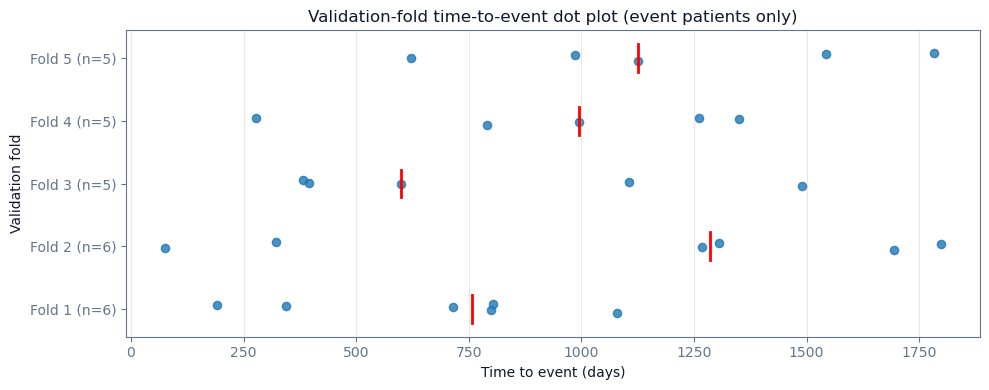

In [10]:
# Dot plot of time-to-event distribution per validation fold (events only)

fold_splits = manual_splits if 'manual_splits' in globals() else cv

plot_rows = []
for fold_id, (_, va_idx) in enumerate(fold_splits, start=1):
    va_times = time_col.iloc[va_idx]
    va_events = event_col.iloc[va_idx].astype(int)

    event_times = va_times[va_events == 1]
    for t in event_times:
        plot_rows.append({"fold": fold_id, "time": float(t)})

event_dot_df = pd.DataFrame(plot_rows)

if event_dot_df.empty:
    print("No events found in validation folds.")
else:
    fig, ax = plt.subplots(figsize=(10, 4))

    rng = np.random.default_rng(42)
    y_jitter = event_dot_df["fold"].values + rng.uniform(-0.08, 0.08, size=len(event_dot_df))
    ax.scatter(event_dot_df["time"], y_jitter, alpha=0.8, s=35)

    # Median event time per fold
    medians = event_dot_df.groupby("fold")["time"].median()
    for f, m in medians.items():
        ax.plot([m, m], [f - 0.22, f + 0.22], color="red", linewidth=2)

    counts = event_dot_df["fold"].value_counts().sort_index()
    ax.set_yticks(sorted(event_dot_df["fold"].unique()))
    ax.set_yticklabels([f"Fold {f} (n={counts.get(f, 0)})" for f in sorted(event_dot_df["fold"].unique())])

    ax.set_xlabel("Time to event (days)")
    ax.set_ylabel("Validation fold")
    ax.set_title("Validation-fold time-to-event dot plot (event patients only)")
    ax.grid(axis="x", alpha=0.3)

    plt.tight_layout()
    plt.show()

## Continuing

In [10]:
# alpha_range = np.logspace(-5, -1, 30)
# l1_ratio_range = [0.001, 0.01, 0.1, 0.5, 0.8, 1.0]

# alpha_range = [0.000853168]
# l1_ratio_range = [1.0]

alpha_range = [0.000621017]
l1_ratio_range = [1.0]

n_controls = ["Full"]

metrics = ['c-index']

In [8]:
results_df, summary_df, best_params = subsampling_repeated_grid_search(
                                     subsampling, x_train, y_train, alpha_range, l1_ratio_range, 
                                     controls_per_case_range=n_controls, metrics=metrics, feature_columns=feature_columns,
                                     event_col='Recurrence', 
                                     time_col='Survival days',
                                     scale_data=True, scaler_type='minmax',
                                     continuous_features=continuous_features,
                                     use_sample_weights=False, weight_ratio=None,
                                     n_splits=4, n_repeats=5, base_random_state=42,
                                     verbose=True, fit_timeout=10)

SUBSAMPLING REPEATED GRID SEARCH
Controls per case: ['Full']
L1 ratios: [0.001, 0.01, 0.1, 0.5, 0.8, 1.0]
Alphas: 30 values from 1.00e-05 to 1.00e-01
Total hyperparameter combinations: 180
Folds per repetition: 4
Repetitions: 5
Total evaluations: 3600
Scaling: Yes (minmax)
Sample weights: No

[1/180] controls=Full (no subsampling), l1=0.001, alpha=1.00e-05 (elapsed: 0.0min, est. remaining: 0.0min)
⚠️  Warning: Model fitting failed with error: Model fit exceeded 10s timeout
  ⏭️  c-index missing at repeat 1, fold 1 — skipping remaining folds/repeats for this combination
[2/180] controls=Full (no subsampling), l1=0.001, alpha=1.37e-05 (elapsed: 0.2min, est. remaining: 15.1min)
⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing alpha.
  ⏭️  c-index missing at repeat 1, fold 1 — skipping remaining folds/repeats for this combination
[3/180] controls=Full (no subsampling), l1=0.001, alpha=1.89e-05 (elapsed: 0.3min, est. remaining

In [9]:
cox_clean = clean_cox_data(summary_df)
cox_clean.to_csv('cox_noRT.csv', index=False)

  Checked 20 c-index fold columns and 0 c-index-ipcw fold columns
  Removed 78 rows with missing fold values (180 -> 102)


In [28]:
# ---- Extend the existing whole-cohort optimism bootstrap (500 reps, seed 42) to also ----
# ---- track time-dependent AUC at each half-yearly horizon, alongside the c-index it reports.
# This does not change the bootstrap draws (the RNG state only depends on n_bootstraps /
# base_random_state, not on which metrics are requested), so c_apparent/c_boot/c_test/c_final
# below are numerically unchanged -- this only adds app_auc_*/boot_auc_*/test_auc_*/optimism_auc_*
# columns to bootstrap_df. Unlike the Section 1 cells above (which call cumulative_dynamic_auc
# directly on any day value), this path dispatches on named metric strings that must match a key
# in the TIME_POINTS lookup inside subsampling_model_evaluation (functions/repeated_cv.py) -- not
# dynamic to an arbitrary horizon. That lookup now also has 1.5y/2.5y/3.5y/4.5y keys, so the list
# below can use them; a horizon missing from that dict would silently come back as NaN instead.
auc_metrics = ['auc-6m', 'auc-1y', 'auc-1.5y', 'auc-2y', 'auc-2.5y', 'auc-3y', 'auc-3.5y', 'auc-4y', 'auc-4.5y', 'auc-5y']


In [11]:
results_df, summary_df, best_params, bootstrap_df = subsampling_bootstrap_optimism_grid_search(survival_dataset, data_x, data_y, alpha_range, l1_ratio_range,
                                               n_controls, feature_columns,
                                               event_col='Regional LN recurrence',
                                               time_col='Survival days',
                                               scale_data=True, scaler_type='minmax',
                                               continuous_features=continuous_features,
                                               use_sample_weights=False, weight_ratio=None,
                                               n_bootstraps=500, base_random_state=42,
                                               verbose=True, metrics=metrics, return_bootstrap_df=True, fit_timeout=None,
                                               collect_coefficients=True,
                                               require_complete_bootstraps=False
                                               )

SUBSAMPLING STRATIFIED BOOTSTRAP OPTIMISM GRID SEARCH
Controls per case: ['Full']
L1 ratios: [1.0]
Alphas: 1 values from 6.21e-04 to 6.21e-04
Bootstrap runs per combination: 500
Total hyperparameter combinations: 1
Total model loops (B/C runs): 500
Scaling: Yes (minmax)
Sample weights: No

[1/1] controls=Full (no subsampling), l1=1.000, alpha=6.21e-04 (elapsed: 0.0min, est. remaining: 0.0min)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)


⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing alpha.
⚠️  Warning: Model fitting failed with error: Numerical error, because weights are too large. Consider increasing alpha.
  ⚠️  c-index missing at bootstrap 83/500 — continuing (require_complete_bootstraps=False)


c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site-packages\sksurv\linear_model\coxph.py:125: RuntimeWarning: overflow encountered in exp
  risk_score = np.exp(linear_predictor)
c:\Users\Joao Goncalves\anaconda3\envs\survival-env\Lib\site


BOOTSTRAP OPTIMISM GRID SEARCH COMPLETE
Total time: 12.7 minutes




In [12]:
bootstrap_df.to_csv('cox_bootstrap_noRT.csv', index=False)

In [15]:
import pandas as pd

# bootstrap_results = pd.read_csv('cox_bootstrap_results.csv')
bootstrap_results = bootstrap_df.copy()

ci_95 = bootstrap_results.quantile([0.025, 0.975], numeric_only=True).T
ci_95.columns = ['Lower 95% CI', 'Upper 95% CI']

print(ci_95)


                  Lower 95% CI  Upper 95% CI
alpha                 0.000621      0.000621
l1_ratio              1.000000      1.000000
bootstrap_idx        12.475000    486.525000
bootstrap_seed    10054.475000  10528.525000
c_apparent            0.925703      0.925703
c_boot                0.885728      0.969478
c_test                0.876018      0.925988
optimism             -0.019448      0.067896
c_final               0.857806      0.945151
app_c_index           0.925703      0.925703
boot_c_index          0.885728      0.969478
test_c_index          0.876018      0.925988
optimism_c_index     -0.019448      0.067896


In [ ]:
import pandas as pd

bootstrap_results = pd.read_csv('cox_bootstrap_results_fulldata.csv')

ci_95 = bootstrap_results.quantile([0.025, 0.975], numeric_only=True).T
ci_95.columns = ['Lower 95% CI', 'Upper 95% CI']

print(ci_95)

                                                    Lower 95% CI  Upper 95% CI
alpha                                                   0.000853      0.000853
l1_ratio                                                1.000000      1.000000
bootstrap_idx                                          12.475000    486.525000
bootstrap_seed                                      10054.475000  10528.525000
c_apparent                                              0.920007      0.920007
c_boot                                                  0.871541      0.966513
c_test                                                  0.878550      0.921018
optimism                                               -0.027114      0.065929
c_final                                                 0.854078      0.947121
coef_Age                                               -0.501844      0.000000
coef_Ki67 positive cells (%) at CB                      0.000000      0.000000
coef_Conventional RT fraction                       

### Time-dependent AUC(t): whole-cohort bootstrap CI band vs. held-out test

Same event-stratified, optimism-corrected bootstrap as the C-index above (500 replicates over the whole 3228-patient/27-event cohort, seed 42) -- `subsampling_bootstrap_optimism_grid_search` was just extended to also score `auc-6m`, `auc-1y`, `auc-1.5y`, ... `auc-5y` (every 0.5y) per replicate, so this reuses the exact same 500 resamples as the reported C-index CI rather than a fresh bootstrap. For each horizon: `auc_final = app_auc - optimism_auc`, matching the `c_final = c_apparent - optimism` construction used for the headline C-index above; the band is the 2.5th/97.5th percentile of that per-replicate `auc_final` distribution.

Unlike the unbootstrapped Section 1 above, this half is *not* dynamic to an arbitrary horizon: each metric name (`auc-1.5y`, ...) is looked up against a fixed `TIME_POINTS` dict inside `subsampling_model_evaluation` (`functions/repeated_cv.py`), which now has the half-year keys added -- a horizon missing from that dict comes back as NaN rather than erroring.

Overlaid: the true held-out test AUC(t) (`auc_evolution_df['auc_test']`, computed above from `x_test`/`y_test`, fold 0 of the grouped 5-fold split -- a patient set that never enters this bootstrap, which resamples the whole cohort). This is the only genuinely out-of-sample curve in the figure; the band and its center use in-sample/whole-cohort resubstitution in some form, same caveat as the C-index bootstrap above.

Caveat: `Regional LN recurrence` is treated as the sole event with death/distant-metastasis as independent censoring, same convention as the rest of this notebook -- see `competing_risks_check.py` for the estimated size of the resulting bias (~+2.6% relative at 5y, larger in the top-risk group).


In [31]:
# Capture now -- the cell below reloads `bootstrap_df` from a cached CSV for the c-index
# section that follows, which would silently overwrite these new auc_* columns.
bootstrap_df_auc = bootstrap_df.copy()


In [32]:
# ---- Optimism-corrected AUC(t) per horizon, same construction as c_final above ----
auc_horizon_years = {'6m': 0.5, '1y': 1, '1.5y': 1.5, '2y': 2, '2.5y': 2.5, '3y': 3, '3.5y': 3.5, '4y': 4, '4.5y': 4.5, '5y': 5}

auc_ci_rows = []
for h, year in auc_horizon_years.items():
    col = f'auc_{h}'
    app_col, opt_col = f'app_{col}', f'optimism_{col}'
    final_vals = bootstrap_df_auc[app_col] - bootstrap_df_auc[opt_col]
    lo, hi = final_vals.quantile([0.025, 0.975])
    auc_ci_rows.append({
        'year': year,
        'auc_apparent': bootstrap_df_auc[app_col].iloc[0],
        'auc_final_mean': final_vals.mean(),
        'auc_final_lo': lo,
        'auc_final_hi': hi,
        'n_replicates': int(final_vals.notna().sum()),
    })

auc_ci_df = pd.DataFrame(auc_ci_rows)
print(auc_ci_df.to_string(index=False))


 year  auc_apparent  auc_final_mean  auc_final_lo  auc_final_hi  n_replicates
  0.5      0.998754        0.998855      0.997192      1.001246           322
  1.0      0.967316        0.953706      0.894303      1.006294           496
  1.5           NaN             NaN           NaN           NaN             0
  2.0      0.980385        0.970657      0.937972      0.997713           498
  2.5           NaN             NaN           NaN           NaN             0
  3.0      0.956362        0.941908      0.879773      1.005954           498
  3.5           NaN             NaN           NaN           NaN             0
  4.0      0.928885        0.905774      0.849498      0.953367           498
  4.5           NaN             NaN           NaN           NaN             0
  5.0      0.844301        0.808529      0.719684      0.898926           498


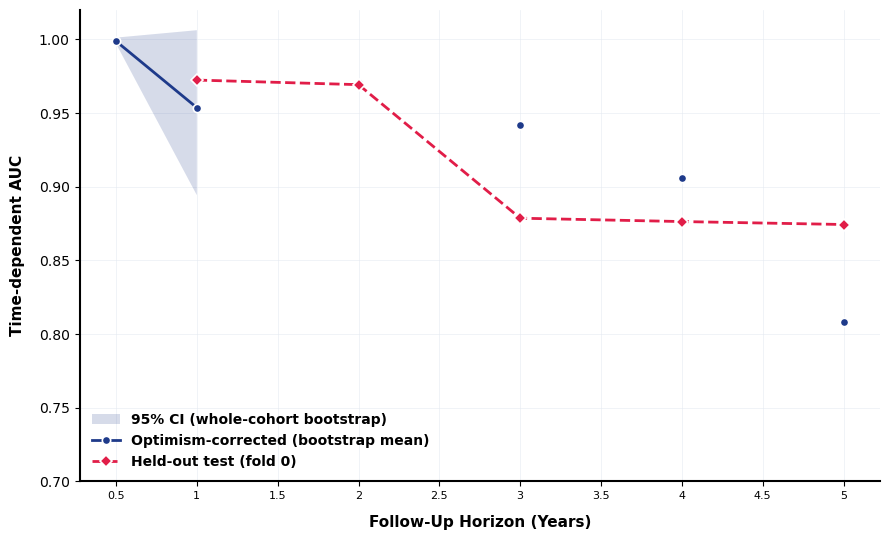

In [33]:
# ---- Plot: whole-cohort bootstrap CI band for AUC(t), with held-out test overlaid ----
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.set_facecolor('none')

ax.axhline(0.5, color=MUTED, linestyle='--', linewidth=1.2, zorder=1)

ax.fill_between(auc_ci_df['year'], auc_ci_df['auc_final_lo'], auc_ci_df['auc_final_hi'],
                 color=NAVY, alpha=0.18, lw=0, zorder=2,
                 label='95% CI (whole-cohort bootstrap)')
ax.plot(auc_ci_df['year'], auc_ci_df['auc_final_mean'], color=NAVY, linewidth=2,
        marker='o', markersize=6, markeredgecolor='white', markeredgewidth=1.2,
        zorder=3, label='Optimism-corrected (bootstrap mean)')
ax.plot(auc_evolution_df['year'], auc_evolution_df['auc_test'], color=CRIMSON,
        linewidth=2, linestyle='--', marker='D', markersize=6,
        markeredgecolor='white', markeredgewidth=1.2, zorder=4,
        label='Held-out test (fold 0)')

ax.set_xlabel('Follow-Up Horizon (Years)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('Time-dependent AUC', fontsize=11, fontweight='bold', labelpad=10)
_auc_ci_year_ticks = auc_ci_df['year'].to_numpy()
ax.set_xticks(_auc_ci_year_ticks)
ax.set_xticklabels([f'{y:g}' for y in _auc_ci_year_ticks], fontsize=8)
y_floor = float(min(auc_ci_df['auc_final_lo'].min(), auc_evolution_df['auc_test'].min()))
ax.set_ylim(max(0.0, 0.7), 1.02)
ax.grid(color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(1.5)
ax.spines['bottom'].set_linewidth(1.5)

leg = ax.legend(loc='lower left', frameon=False)
for text in leg.get_texts():
    text.set_fontweight('bold')

plt.tight_layout()
plt.savefig('auc_bootstrap_ci_transparent.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('auc_bootstrap_ci_transparent.pdf', dpi=300, transparent=True, bbox_inches='tight')
plt.show()


In [4]:
bootstrap_df = pd.read_csv('cox_bootstrap_results.csv')

In [ ]:
c_boot_source = bootstrap_df.copy()

overall_ci = c_boot_source['c_final'].quantile([0.025, 0.975])
print('Overall c_final percentiles:')
print(f"2.5th percentile:  {overall_ci.loc[0.025]:.6f}")
print(f"97.5th percentile: {overall_ci.loc[0.975]:.6f}")

if {'n_controls', 'alpha', 'l1_ratio'}.issubset(c_boot_source.columns):
    per_combo_ci = (
        c_boot_source.groupby(['n_controls', 'alpha', 'l1_ratio'])['c_final']
        .quantile([0.025, 0.975])
        .unstack()
        .reset_index()
        .rename(columns={0.025: 'c_final_p2_5', 0.975: 'c_final_p97_5'})
    )
    print('\nPer-combination c_final percentiles:')
    print(per_combo_ci.to_string(index=False))
else:
    per_combo_ci = None

# ---- Full bootstrap summary: apparent, in-bag, test, optimism, optimism-corrected ----
_final_lo, _final_hi = c_boot_source['c_final'].quantile([0.025, 0.975])
_boot_lo, _boot_hi = c_boot_source['c_boot'].quantile([0.025, 0.975])
_test_lo, _test_hi = c_boot_source['c_test'].quantile([0.025, 0.975])
_opt_lo, _opt_hi = c_boot_source['optimism'].quantile([0.025, 0.975])

print(f"
C-index bootstrap summary (n={len(c_boot_source)} replicates):")
print(f"  apparent                 {c_boot_source['c_apparent'].iloc[0]:.4f}")
print(f"  in-bag             mean  {c_boot_source['c_boot'].mean():.4f}   "
      f"[{_boot_lo:.4f}, {_boot_hi:.4f}]")
print(f"  test (out-of-bag)  mean  {c_boot_source['c_test'].mean():.4f}   "
      f"[{_test_lo:.4f}, {_test_hi:.4f}]")
print(f"  optimism           mean  {c_boot_source['optimism'].mean():+.4f}   "
      f"[{_opt_lo:+.4f}, {_opt_hi:+.4f}]")
print(f"  optimism-corrected mean  {c_boot_source['c_final'].mean():.4f}   "
      f"[{_final_lo:.4f}, {_final_hi:.4f}]")


### Bootstrap confidence intervals for Cox coefficients

Reuses the Step-B bootstrap models already fit above (`collect_coefficients=True`) -- no extra model fits. Shows every feature with a non-zero coefficient in the final model (`coef_df`, fit on the full dataset above); the point plotted is that final-model coefficient, so the chart always agrees with the model's actual reported coefficients. The interval is the 2.5th/97.5th percentile of that feature's coefficient across only the bootstraps where it was actually selected (non-zero) -- bootstraps where the penalty dropped it to zero are excluded from the interval rather than averaged in, since blending "dropped" and "kept" runs would bias the interval toward zero and hide unstable-but-strong effects. Marker size/opacity encode how often the feature was selected out of the total bootstraps, and the exact count is printed on each row.

In [13]:
# ---- Per-feature bootstrap CI from the Step-B coefficients captured above ----
# A feature is "selected" in a given bootstrap when the L1 penalty leaves its
# coefficient non-zero. The interval only uses the bootstraps where the
# variable was actually selected (the runs where it was dropped to zero are
# excluded, not averaged in) -- otherwise a rare-but-strong effect would be
# pulled toward zero and look indistinguishable from "no effect". The point
# itself is the coefficient from the final model (coef_df, above), not a
# bootstrap summary -- so the chart always agrees with the model's actual
# reported coefficients.

# Display names for the chart -- edit the values freely, the keys must match
# the raw column names in coef_df/feature_columns. Any feature not listed here
# (e.g. if the final model's selected variables change later) falls back to
# its raw column name.
FEATURE_NAME_MAP = {
    'Oestrogen receptor status at CB': 'ER status at CB',
    'Neoadjuvant (Only) therapy with biological drugs': 'Neoadjuvant (Only) therapy with biological drugs',
    'Total administered dose': 'Total administered radiotherapy dose (Gy)',
    'Isotype at CB_2.0': 'Isotype at CB - Lobular',
    'Isotype at CB_4.0': 'Isotype at CB - Other',
    'Radiotherapy on supraclavicular area': 'Radiotherapy on supraclavicular area',
    'Treatment in association with chemotherapy': 'Hormone therapy associated with chemotherapy protocol',
    'Grade at CB_3.0': 'High Grade at CB',
    'Adjuvant therapy using biological drugs': 'Adjuvant therapy with biological drugs',
}

def prettify_feature_name(name):
    return FEATURE_NAME_MAP.get(name, name)

# Reload -- cell 30 above (the c-index bootstrap summary section) overwrites the
# in-memory bootstrap_df with the old cox_bootstrap_results.csv; re-read the fresh
# whole-cohort run (with coefficients) that cell 23 just saved.
bootstrap_df = pd.read_csv('cox_bootstrap_noRT.csv')

coef_cols = [c for c in bootstrap_df.columns if c.startswith('coef_')]
feature_names_from_cols = [c[len('coef_'):] for c in coef_cols]

coef_selection_rows = []
for col, feat in zip(coef_cols, feature_names_from_cols):
    boot_vals = bootstrap_df[col].dropna()
    n_boot = len(boot_vals)
    if n_boot == 0:
        continue

    selected_vals = boot_vals[boot_vals != 0]
    n_selected = len(selected_vals)
    if n_selected == 0:
        continue  # never selected in any bootstrap -- excluded from the chart

    ci_low, ci_high = selected_vals.quantile([0.025, 0.975])
    coef_selection_rows.append({
        'feature': feat,
        'feature_label': prettify_feature_name(feat),
        'n_boot': n_boot,
        'n_selected': n_selected,
        'pct_selected': n_selected / n_boot,
        'ci_low': ci_low,
        'ci_high': ci_high,
    })

coef_selection_df = pd.DataFrame(coef_selection_rows)

# Point estimate: coefficient from the final model fit on the full dataset (coef_df, above)
coef_selection_df = coef_selection_df.merge(coef_df[['feature', 'coefficient']], on='feature', how='left')

# Keep only features the final model actually kept (non-zero coefficient) --
# the bootstrap CI above still only uses the bootstraps where each one was selected.
coef_selection_df = coef_selection_df[coef_selection_df['coefficient'] != 0].reset_index(drop=True)

coef_selection_df['abs_coefficient'] = coef_selection_df['coefficient'].abs()
coef_selection_df = coef_selection_df.sort_values(
    ['pct_selected', 'abs_coefficient'], ascending=False
).reset_index(drop=True)

print(coef_selection_df.to_string(index=False))

coef_selection_df.to_csv('cox_coef_bootstrap_ci.csv', index=False)


                                         feature                                         feature_label  n_boot  n_selected  pct_selected    ci_low   ci_high  coefficient  abs_coefficient
                 Oestrogen receptor status at CB                                       ER status at CB     499         499      1.000000 -3.162889 -1.236019    -2.138313         2.138313
Neoadjuvant (Only) therapy with biological drugs      Neoadjuvant (Only) therapy with biological drugs     499         497      0.995992  0.500534  2.857938     1.712996         1.712996
                               Isotype at CB_4.0                                 Isotype at CB - Other     499         457      0.915832  0.076234  2.084033     0.990283         0.990283
            Radiotherapy on supraclavicular area                  Radiotherapy on supraclavicular area     499         453      0.907816  0.050746  1.612838     0.737387         0.737387
                                 Grade at CB_3.0                 

In [3]:
import pandas as pd
coef_selection_df = pd.read_csv('cox_coef_bootstrap_ci.csv')

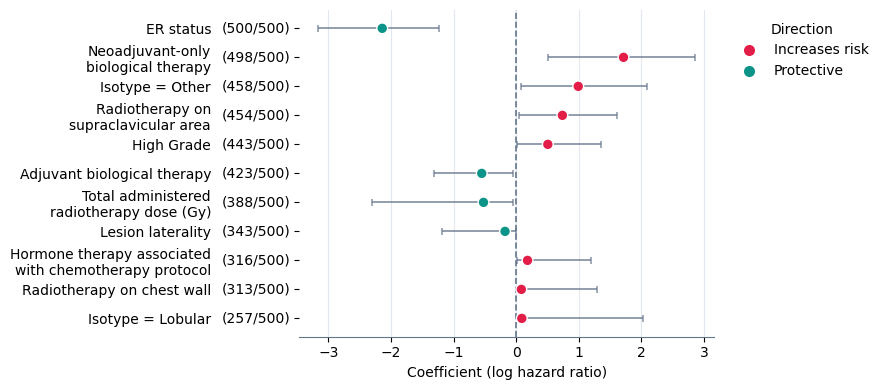

In [7]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import textwrap

FEATURE_NAME_MAP = {
    'ER status at CB': 'ER status',
    'Neoadjuvant (Only) therapy with biological drugs': 'Neoadjuvant-only       biological therapy',
    'Radiotherapy on supraclavicular area': 'Radiotherapy on supraclavicular area',
    'Isotype at CB - Lobular': 'Isotype = Lobular',
    'Isotype at CB - Other': 'Isotype = Other',
    'High Grade at CB': 'High Grade',
    'Adjuvant therapy with biological drugs': 'Adjuvant biological therapy',
    'Side location of the lesion': 'Lesion laterality', 
    'Hormone therapy associated with chemotherapy protocol': 'Hormone therapy associated with chemotherapy protocol'
}

# ---- Coefficient plot: final-model coefficients with bootstrap selection CI ----
TEAL = '#0D9488'
CRIMSON = '#E11D48'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'
TEXT_COLOR = '#000000'
POINT_SIZE = 60

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': TEXT_COLOR,
    'axes.labelcolor': TEXT_COLOR,
    'xtick.color': TEXT_COLOR,
    'ytick.color': TEXT_COLOR,
    'axes.edgecolor': MUTED,
})

plot_df = coef_selection_df.sort_values(
    ['pct_selected', 'abs_coefficient'], ascending=True
).reset_index(drop=True)

y_pos = np.arange(len(plot_df))
point_colors = [CRIMSON if c > 0 else TEAL for c in plot_df['coefficient']]

fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(plot_df))))
ax.set_facecolor('none')
fig.patch.set_alpha(0.0)

ax.axvline(0, color=MUTED, linestyle='--', linewidth=1.2, zorder=1)

ax.hlines(y_pos, plot_df['ci_low'], plot_df['ci_high'], color=MUTED, linewidth=1.4, alpha=0.7, zorder=2)
cap_height = 0.12
for y, lo, hi in zip(y_pos, plot_df['ci_low'], plot_df['ci_high']):
    ax.vlines([lo, hi], y - cap_height, y + cap_height, color=MUTED, linewidth=1.2, alpha=0.7, zorder=2)

ax.scatter(plot_df['coefficient'], y_pos, s=POINT_SIZE, color=point_colors, zorder=3,
           edgecolor='white', linewidth=1)

ax.set_yticks(y_pos)

# 1. Set ONLY the wrapped feature names as the y-tick labels
max_width = 30
ax.set_yticklabels([
    textwrap.fill(FEATURE_NAME_MAP.get(label, label), width=max_width)
    for label in plot_df['feature_label']
])

# 2. Push the text labels further to the left to create a dedicated column space
# (You can adjust 'pad=75' up or down to change the gap between text and numbers)
ax.tick_params(axis='y', pad=60)

# 3. Draw the numbers in a perfectly right-aligned column in that empty space
for y, n, n_boot in zip(y_pos, plot_df['n_selected'], plot_df['n_boot']):
    # x=-0.02 places them just to the left of the y-axis line
    # Added +2 to both n and n_boot
    ax.text(-0.02, y, f"({n + 1}/{n_boot + 1})", 
            transform=ax.get_yaxis_transform(), 
            ha='right', va='center', color=TEXT_COLOR)

ax.set_xlabel('Coefficient (log hazard ratio)')
ax.grid(axis='x', color=GRID_COLOR, linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

# Direction legend
sign_legend = [
    Line2D([0], [0], marker='o', color='none', markerfacecolor=CRIMSON, markeredgecolor='white',
           markersize=9, label='Increases risk'),
    Line2D([0], [0], marker='o', color='none', markerfacecolor=TEAL, markeredgecolor='white',
           markersize=9, label='Protective'),
]
sign_leg = ax.legend(handles=sign_legend, loc='upper left', bbox_to_anchor=(1.02, 1.0),
                     frameon=False, title='Direction')

plt.tight_layout()
plt.savefig('cox_coef_forest_plot.png', dpi=300, transparent=True,
            bbox_inches='tight', bbox_extra_artists=(sign_leg,))
plt.savefig('cox_coef_forest_plot.pdf', transparent=True,
            bbox_inches='tight', bbox_extra_artists=(sign_leg,))
plt.show()

## SurvSHAP global feature importance

One point estimate on the **whole cohort** (3228 patients, 27 events after the 5-year
cut-off above) — no bootstrap, no CI, and not the training split.

Background sample, explained sample and timestamp grid are pinned the same way in
`cox.ipynb`, `rsf.ipynb`, `gbm.ipynb` and `ssvm.ipynb`, since `aggregated_change` (a
trapezoid integral of mean |SurvSHAP(t)| over that grid) is only comparable across
models if all three match. `shap_comparison.ipynb` picks up the four
`*_survshap_global_importance.csv` files this section writes.

In [5]:
# --- Shared SurvSHAP protocol (identical text in cox/rsf/gbm/ssvm.ipynb) -----
# Everything below runs on the WHOLE cohort (data_x / data_y: 3228 patients,
# 27 events after the 5-year cut-off applied earlier in this notebook), not on
# the training split. Feature importance is a statement about the cohort, so it
# is estimated from the cohort; the train/test split above exists to report
# out-of-sample discrimination, which is a different question.
#
# Three choices are pinned here, and pinned the same way in all four notebooks,
# because `aggregated_change` is only comparable across models if they share
# them. Both data builds (`data/` and `data/data_cox/`) have identical row
# order, event and time vectors, so the seeds below select the same patients in
# every notebook even though the Cox build has 30 columns and the others 35.
#
#   BACKGROUND (N_BACKGROUND rows, plain random draw)
#       SHAP explains a prediction as a deviation from E[f(X)] over this set,
#       so it has to look like the cohort. A plain random draw keeps the real
#       ~0.84% event prevalence. Forcing every event into the background (what
#       the earlier version of these cells did) makes the reference "average
#       patient" ~25x more recurrence-prone than any real patient and shifts
#       every attribution away from the population it is meant to describe.
#
#   EXPLAINED SET (N_EXPLAINED rows: all 27 events + random non-events)
#       Here the enrichment is deliberate and is the point: global importance
#       is an average over the patients being explained, and a plain random
#       sample of 100 would contain about one event.
#
#   TIMESTAMPS (N_TIMESTAMPS points, 5th-95th percentile of ALL 27 event times)
#       `aggregated_change` is a trapezoid integral over this grid, so the grid
#       must be identical across models. It is therefore derived from data_y
#       itself, never from whichever sample happened to be drawn.
import sys, os
sys.path.insert(0, os.path.abspath('../../../survshap-main/survshap_package'))
from survshap import SurvivalModelExplainer, ModelSurvSHAP

SHAP_SEED    = 42
N_BACKGROUND = 100   # halve to 50 to roughly halve runtime, at some cost in SHAP precision
N_EXPLAINED  = 100
N_TIMESTAMPS = 20
SHAP_B       = 25    # Monte-Carlo paths for calculation_method="sampling" (survshap default)

_event_field, _time_field = data_y.dtype.names
_event = data_y[_event_field]
_time  = data_y[_time_field]
_rng   = np.random.RandomState(SHAP_SEED)

# Background: plain random draw over the whole cohort, prevalence preserved.
shap_background_idx = np.sort(_rng.choice(len(data_x), size=N_BACKGROUND, replace=False))

# Explained set: every event, topped up with random non-events.
_event_idx     = np.where(_event == 1)[0]
_non_event_idx = np.where(_event == 0)[0]
shap_explained_idx = np.sort(np.concatenate([
    _event_idx,
    _rng.choice(_non_event_idx,
                size=max(0, N_EXPLAINED - len(_event_idx)),
                replace=False),
]))

# Shared integration grid, from the full cohort's event times.
shap_timestamps = np.percentile(_time[_event == 1], np.linspace(5, 95, N_TIMESTAMPS))

print(f"cohort           : {len(data_x)} patients, {int(_event.sum())} events "
      f"({100 * _event.mean():.2f}%)")
print(f"SHAP background  : {len(shap_background_idx)} rows, "
      f"{int(_event[shap_background_idx].sum())} events (representative)")
print(f"SHAP explained   : {len(shap_explained_idx)} rows, "
      f"{int(_event[shap_explained_idx].sum())} events (all events + controls)")
print(f"SHAP timestamps  : {N_TIMESTAMPS} points, "
      f"{shap_timestamps.min():.0f}..{shap_timestamps.max():.0f} days")

cohort           : 3228 patients, 27 events (0.84%)
SHAP background  : 100 rows, 1 events (representative)
SHAP explained   : 100 rows, 27 events (all events + controls)
SHAP timestamps  : 20 points, 218..1757 days


In [6]:
# --- Cox: global SurvSHAP on the whole cohort -------------------------------
# Explains `cox_model_full` -- the Coxnet refit on every patient with the tuned
# hyperparameters, built further up this notebook. That is deliberately the same
# model the coefficient forest plot reports, so the SHAP ranking and the
# coefficients describe one object rather than two different fits.
#
# calculation_method="sampling" is the Monte-Carlo Shapley estimator over random
# feature orderings (SHAP_B paths per patient), marginalising over the
# background set. gbm.ipynb and ssvm.ipynb use exactly this; rsf.ipynb uses
# exact TreeSHAP for the same estimand, because a 2000-tree forest is far too
# expensive to evaluate this many times (see the note in that notebook).
cox_shap_explainer = SurvivalModelExplainer(
    model=cox_model_full,
    data=x_full_scaled.iloc[shap_background_idx].reset_index(drop=True),
    y=data_y[shap_background_idx],
)

cox_global_survshap = ModelSurvSHAP(
    calculation_method="sampling",
    aggregation_method="integral",
    B=SHAP_B,
    random_state=SHAP_SEED,
)
cox_global_survshap.fit(
    cox_shap_explainer,
    new_observations=x_full_scaled.iloc[shap_explained_idx].reset_index(drop=True),
    timestamps=shap_timestamps,
)

cox_survshap_importance = (
    cox_global_survshap.result[["variable_name", "aggregated_change"]]
    .sort_values("aggregated_change", ascending=False)
    .reset_index(drop=True)
)
cox_survshap_importance.to_csv("cox_survshap_global_importance.csv", index=False)
print(cox_survshap_importance.to_string(index=False))


  0%|          | 0/100 [00:00<?, ?it/s]


  0%|          | 0/25 [00:00<?, ?it/s]


  4%|▍         | 1/25 [00:00<00:10,  2.29it/s]


  8%|▊         | 2/25 [00:00<00:09,  2.48it/s]


 12%|█▏        | 3/25 [00:01<00:08,  2.54it/s]


 16%|█▌        | 4/25 [00:01<00:09,  2.17it/s]

... (2,793 outputs left out)


100%|██████████| 25/25 [00:05<00:00,  4.25it/s]



100%|██████████| 100/100 [11:54<00:00,  5.89s/it]


100%|██████████| 100/100 [11:54<00:00,  7.15s/it]

                                            variable_name  aggregated_change
                          Oestrogen receptor status at CB          15.621658
         Neoadjuvant (Only) therapy with biological drugs          10.723725
                                        Isotype at CB_4.0           6.565000
                     Radiotherapy on supraclavicular area           6.050957
                                          Grade at CB_3.0           4.205448
                                  Total administered dose           2.117239
                  Adjuvant therapy using biological drugs           1.472640
                              Side location of the lesion           1.257135
               Treatment in association with chemotherapy           1.201738
                               Radiotherapy on chest wall           0.267830
                                        Isotype at CB_2.0           0.164289
                                                      Age           0.000000

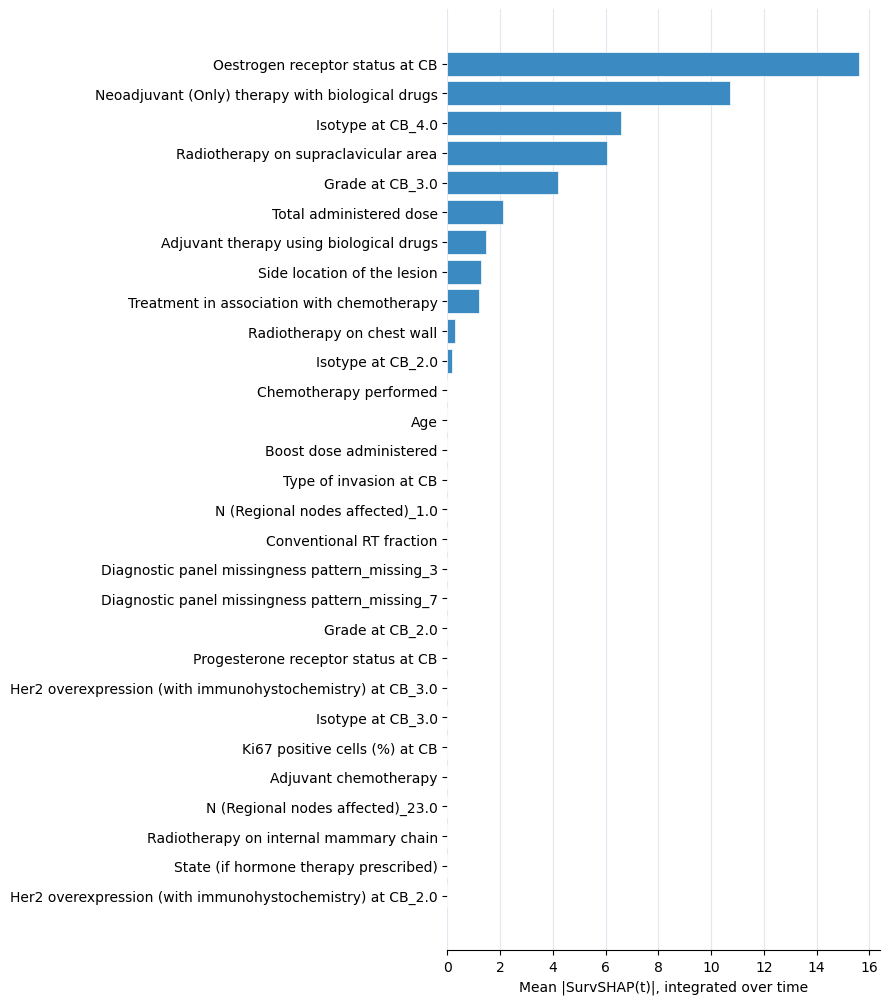

In [7]:
# --- Cox SurvSHAP global importance plot ---
# aggregated_change is a magnitude (mean |SurvSHAP(t)| integrated over the shared
# timestamp grid); it carries no sign or direction, so a single colour is used.
plot_df = cox_survshap_importance.sort_values('aggregated_change', ascending=True).reset_index(drop=True)
y_pos = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(9, max(4, 0.35 * len(plot_df))))
ax.set_facecolor('none')
fig.patch.set_alpha(0.0)
ax.barh(y_pos, plot_df['aggregated_change'], color=plt.cm.Blues(0.65),
        edgecolor='white', linewidth=0.5, zorder=3)
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['variable_name'])
ax.set_xlabel('Mean |SurvSHAP(t)|, integrated over time')
ax.grid(axis='x', color='#E2E8F0', linewidth=0.8, zorder=0)
ax.set_axisbelow(True)
for spine in ['top', 'right', 'left']:
    ax.spines[spine].set_visible(False)

plt.tight_layout()
plt.savefig('cox_survshap_global_importance.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('cox_survshap_global_importance.pdf', transparent=True, bbox_inches='tight')
plt.show()

In [ ]:
from math import sqrt
from scipy.stats import t as student_t

# 4-fold cross-validation on the training data
event_labels_train = y_train["event"].astype(int)

skf_4fold = StratifiedKFold(n_splits=4, shuffle=True, random_state=12)
cv_4fold_splits = list(skf_4fold.split(x_train, event_labels_train))

# ---- Fill these values later ----
mean_diff_input = 0.900927113
std_diff_input = 0.04858493
n_train_input = 1937
n_test_input = 645
n_evaluations_input = 20        # e.g., 5 folds * 4 repeats

ci_results = corrected_resampled_t_confidence_interval(
    mean_diff=mean_diff_input,
    std_diff=std_diff_input,
    n_train=n_train_input,
    n_test=n_test_input,
    n_evaluations=n_evaluations_input,
    alpha=0.05,
 )

print(f"Corrected SE: {ci_results['standard_error_corrected']:.6f}")
print(f"95% CI: [{ci_results['ci_low']:.6f}, {ci_results['ci_high']:.6f}]")

Corrected SE: 0.030067
95% CI: [0.837995, 0.963859]


In [ ]:
binary_variables = ['Adjuvant therapy using biological drugs', 'Trastuzumab or other drugs', 'Radiotherapy (RT) performed', 
 'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain', 
 'Endocrine therapy performed', 'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 
 'Chemotherapy performed', 'Adjuvant chemotherapy', 'Type of invasion at CB', 'Progesterone receptor status at CB',  'Side location of the lesion', 
 'Source of referral', ]
 
continuous_variables = ['Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 'Age', 'Ki67 positive cells (%) at CB',
                         'Grade at CB']

ohe = {
    'N (Regional nodes affected)': ['N (Regional nodes affected)_1.0', 'N (Regional nodes affected)_23'],
    'Oestrogen receptor status at CB': ['Oestrogen receptor status at CB_0.0', 'Oestrogen receptor status at CB_1.0'],
    'Her2 overexpression (with immunohystochemistry) at CB': ['Her2 overexpression (with immunohystochemistry) at CB_1.0', 'Her2 overexpression (with immunohystochemistry) at CB_2.0', 'Her2 overexpression (with immunohystochemistry) at CB_3.0'],
    'Number identifying the lesion in the patient': ['Number identifying the lesion in the patient_2', 'Number identifying the lesion in the patient_34'],
    'Classification with respect to other lesions': ['Classification with respect to other lesions_2.0', 'Classification with respect to other lesions_3.0'],
    'Isotype at CB': ['Isotype at CB_1.0', 'Isotype at CB_2.0', 'Isotype at CB_3.0', 'Isotype at CB_4.0'],
    'Disease extent': ['Disease extent_1.0', 'Disease extent_2.0']
}

In [4]:
# Define time points for calibration analysis (1, 2, 3, 4, 5 years)
time_points = [365, 730, 1095, 1460, 1825]  # in days

# Use the best model parameters found earlier
best_params_for_calibration = {
    'alphas': [0.000464159],
    'l1_ratio': 1.0,
    'fit_baseline_model': True
    }

n_controls=["Full"]

# predictions_df = pd.read_csv("cox_calibration_predictions.csv")

In [ ]:
# Collect predictions using repeated CV (same methodology as training)
predictions_df, threshold_metrics_df = collect_cv_predictions_for_calibration(
    model_class=CoxnetSurvivalAnalysis,
    X=x_train,
    y=y_train,
    model_params=best_params_for_calibration,
    time_points=time_points,
    scale_data=True,
    scaler_type='minmax', 
    continuous_features=continuous_features,
    random_state=None,
    n_jobs=-1,
    n_controls_per_case=None,  
    dataset=subsampling,
    feature_columns=feature_columns,
    event_col='Regional LN recurrence',
    time_col='Survival days',
    n_splits=4,
    n_repeats=1, 
    base_random_state=42,
    recalibrate=False,
    calculate_threshold=True,
    verbose=True
)

# Save predictions for later analysis
predictions_df.to_csv('cox_calibration_predictions.csv', index=False)
threshold_metrics_df.to_csv('cox_threshold_metrics.csv', index=False)
print(f"\nPredictions saved to 'cox_calibration_predictions.csv'")
print(f"Threshold metrics saved to 'cox_threshold_metrics.csv'")

Time points: [365, 730, 1095, 1460, 1825]
CV: 1 repeats x 4 folds = 4 models
Threshold mode: ON (optimize per-fold, per-timepoint thresholds)

Repeat 1/1
  Fold 1/4... Creating model with params: {'alphas': [0.000464159], 'l1_ratio': 1.0, 'fit_baseline_model': True}
Done
  Fold 2/4... Creating model with params: {'alphas': [0.000464159], 'l1_ratio': 1.0, 'fit_baseline_model': True}
Done
  Fold 3/4... Creating model with params: {'alphas': [0.000464159], 'l1_ratio': 1.0, 'fit_baseline_model': True}
Done
  Fold 4/4... Creating model with params: {'alphas': [0.000464159], 'l1_ratio': 1.0, 'fit_baseline_model': True}
Done

Total predictions collected: 2582
Unique samples: 2582
Total threshold-metric rows: 20

Predictions saved to 'cox_calibration_predictions.csv'
Threshold metrics saved to 'cox_threshold_metrics.csv'


In [ ]:
# Column-wise statistics for all numeric columns
numeric_cols = threshold_metrics_df.select_dtypes(include=[np.number]).columns

col_stats = threshold_metrics_df[numeric_cols].describe(
    percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
).T

col_stats["missing"] = threshold_metrics_df[numeric_cols].isna().sum()
col_stats["missing_pct"] = (col_stats["missing"] / len(threshold_metrics_df) * 100).round(2)
col_stats["unique"] = threshold_metrics_df[numeric_cols].nunique()

print("Column-wise statistics (overall):")
print(col_stats.round(4).to_string())

# Optional: statistics by time point for key model metrics
metric_cols = ["sensitivity", "specificity", "PPV", "NPV", "accuracy", "F1_score", "threshold"]

stats_by_time = (
    threshold_metrics_df.groupby("time_days")[metric_cols]
    .describe(percentiles=[0.25, 0.5, 0.75])
    .round(4)
)

print("\nColumn-wise statistics grouped by time_days:")
print(stats_by_time.to_string())

Column-wise statistics (overall):
                 count       mean       std        min         1%         5%        25%        50%        75%        95%        99%        max  missing  missing_pct  unique
repeat_idx        20.0     0.0000    0.0000     0.0000     0.0000     0.0000     0.0000     0.0000     0.0000     0.0000     0.0000     0.0000        0          0.0       1
fold_idx          20.0     1.5000    1.1471     0.0000     0.0000     0.0000     0.7500     1.5000     2.2500     3.0000     3.0000     3.0000        0          0.0       4
time_days         20.0  1095.0000  529.5977   365.0000   365.0000   365.0000   730.0000  1095.0000  1460.0000  1825.0000  1825.0000  1825.0000        0          0.0       5
time_years        20.0     3.0000    1.4510     1.0000     1.0000     1.0000     2.0000     3.0000     4.0000     5.0000     5.0000     5.0000        0          0.0       5
threshold         20.0     0.0068    0.0042     0.0018     0.0019     0.0022     0.0039     0.0055   

Jittered risk score plot saved to cox_actually_min_risk_score_distribution.png

Time point 365 days:
  Events: 5, No events: 2427
  Mean survival prob (event): 0.991
  Mean survival prob (no event): 0.998
  Cohen's d: 1.21

Time point 730 days:
  Events: 8, No events: 1891
  Mean survival prob (event): 0.978
  Mean survival prob (no event): 0.997
  Cohen's d: 1.56

Time point 1095 days:
  Events: 13, No events: 1621
  Mean survival prob (event): 0.957
  Mean survival prob (no event): 0.994
  Cohen's d: 1.46

Time point 1460 days:
  Events: 18, No events: 1148
  Mean survival prob (event): 0.945
  Mean survival prob (no event): 0.990
  Cohen's d: 1.10

Time point 1825 days:
  Events: 22, No events: 910
  Mean survival prob (event): 0.935
  Mean survival prob (no event): 0.985
  Cohen's d: 0.91


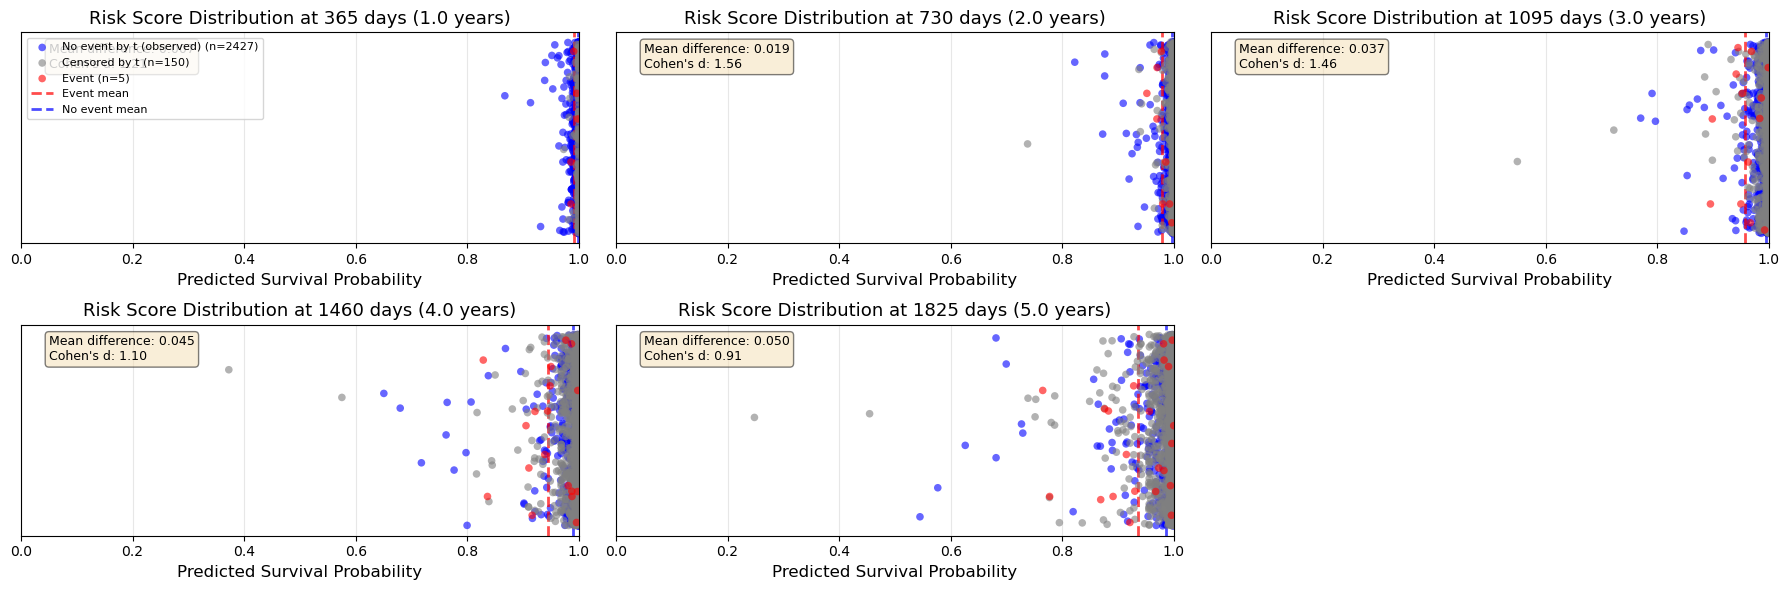

In [ ]:
# Basic usage
fig, axes, stats = plot_jittered_risk_scores(
    predictions_df=predictions_df,
    time_points=time_points,
    figsize=(18, 6),
    save_path='cox_actually_min_risk_score_distribution.png'
)  

# Check separation statistics
for t, stat in stats.items():
    print(f"\nTime point {t} days:")
    print(f"  Events: {stat['n_events']}, No events: {stat['n_no_events']}")
    print(f"  Mean survival prob (event): {stat['event_mean']:.3f}")
    print(f"  Mean survival prob (no event): {stat['no_event_mean']:.3f}")
    print(f"  Cohen's d: {stat['cohens_d']:.2f}")

In [ ]:
# Calculate Brier Score at each time point
brier_scores = {}

for t in time_points:
    col_name = f'pred_surv_{int(t)}d'
    
    # Get predictions and actual outcomes
    df_temp = predictions_df[['sample_idx', 'event', 'time', col_name]].dropna()
    
    # Calculate observed outcome at this time point
    # 1 if survived past time point, 0 if had event before/at time point
    observed = ((df_temp['time'] > t) | 
                ((df_temp['time'] <= t) & (df_temp['event'] == 0))).astype(int)
    
    predicted = df_temp[col_name].values
    
    # Brier Score: mean squared error between predicted and observed
    brier = np.mean((predicted - observed) ** 2)
    
    brier_scores[t] = brier
    print(f"Time point {t} days ({t/365:.1f} years): Brier Score = {brier:.4f}")

# Store in a DataFrame for easy viewing
brier_scores_df = pd.DataFrame([
    {'time_point_days': t, 'time_point_years': t/365, 'brier_score': score}
    for t, score in brier_scores.items()
])

print("\nBrier Scores Summary:")
print(brier_scores_df.to_string(index=False))

Time point 365 days (1.0 years): Brier Score = 0.0019
Time point 730 days (2.0 years): Brier Score = 0.0031
Time point 1095 days (3.0 years): Brier Score = 0.0050
Time point 1460 days (4.0 years): Brier Score = 0.0070
Time point 1825 days (5.0 years): Brier Score = 0.0088

Brier Scores Summary:
 time_point_days  time_point_years  brier_score
             365               1.0     0.001936
             730               2.0     0.003074
            1095               3.0     0.004954
            1460               4.0     0.007010
            1825               5.0     0.008835


Calibration plot saved to cox_actually_calibration_curves.png


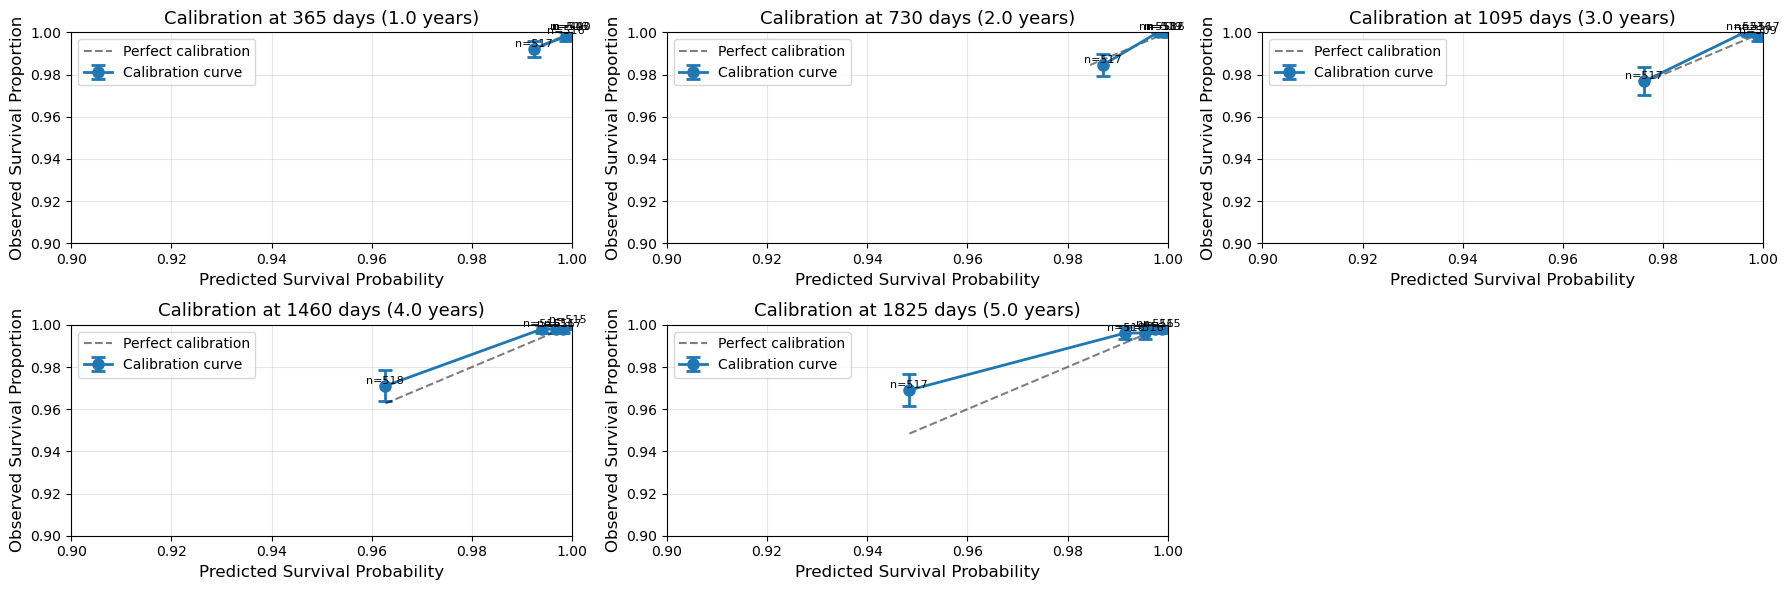

In [ ]:
# Generate calibration curves for all time points
fig, axes, calibration_results = plot_calibration_curves(
    predictions_df=predictions_df,
    time_points=time_points,
    n_bins=5,
    strategy='quantile',  # Equal-sized bins based on prediction quantiles
    figsize=(18, 6),
    save_path='cox_actually_calibration_curves.png',
    xlim=(0.9, 1),
    ylim=(0.9, 1),
    error_bar_type='se'
)

plt.show()

  Processing fold 1/12...
  Processing fold 2/12...
  Processing fold 3/12...
  Processing fold 4/12...
  Processing fold 5/12...
  Processing fold 6/12...
  Processing fold 7/12...
  Processing fold 8/12...
  Processing fold 9/12...
  Processing fold 10/12...
  Processing fold 11/12...
  Processing fold 12/12...

  Collected survival curves for 2582 patients


(<Figure size 1500x1000 with 1 Axes>,
 <Axes: title={'center': 'Individual Patient Survival Curves (CV Predictions)'}, xlabel='Time (days)', ylabel='Predicted Survival Probability'>,
     patient_idx  event    time event_status  n_predictions
 0           211   True   790.0        Event              1
 1           539   True  1799.0        Event              1
 2           662   True  1784.0        Event              1
 3           700   True  1543.0        Event              1
 4           703   True  1106.0        Event              1
 5           751   True  1306.0        Event              1
 6           867   True  1262.0        Event              1
 7           913   True   345.0        Event              1
 8           950   True  1351.0        Event              1
 9           973   True   278.0        Event              1
 10         1024   True   799.0        Event              1
 11         1054   True   986.0        Event              1
 12         1132   True   192.0      

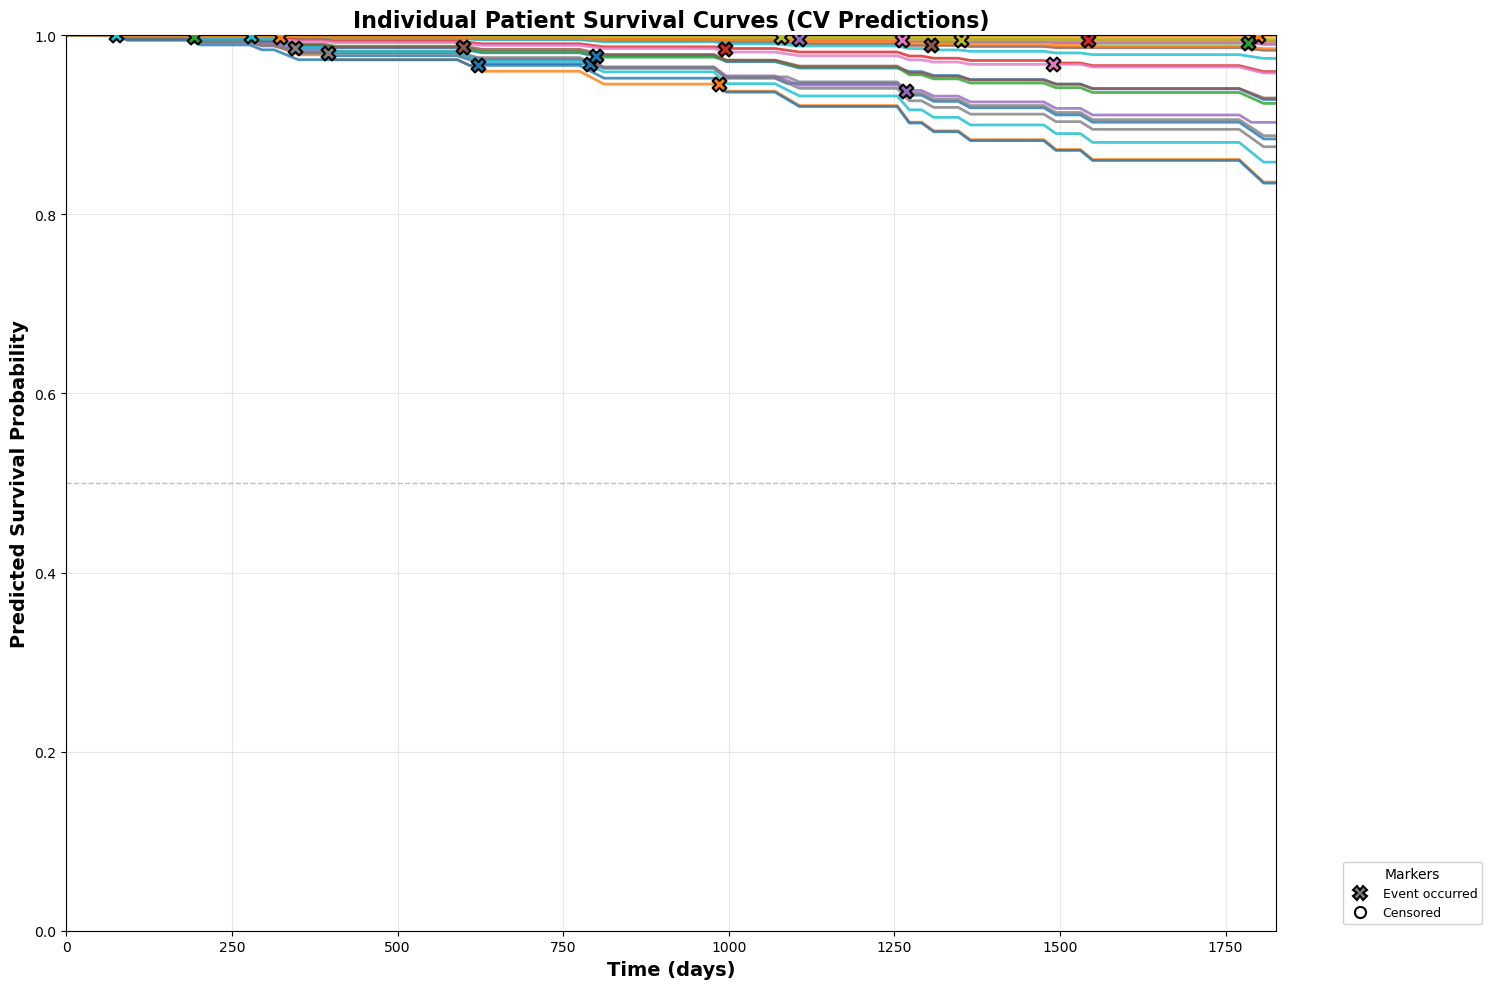

In [ ]:
plot_individual_survival_curves(model_class=CoxnetSurvivalAnalysis, X=x_train, y=y_train, model_params=best_params_for_calibration,
                                    patient_indices=None, 
                                    n_patients=24, select_events_only=True,
                                    scale_data=True, scaler_type='minmax',
                                    continuous_features=continuous_features,
                                    n_controls_per_case=None, dataset=None,
                                    feature_columns=None,
                                    event_col='Regional LN recurrence',
                                    time_col='Survival days',
                                    n_splits=12, n_repeats=1, random_state=42,
                                    time_range=None, n_time_points=100,
                                    figsize=(15, 10), save_path=None,
                                    show_event_markers=True, show_censoring_markers=True,
                                    event_marker_size=100, censoring_marker_size=80,
                                    colormap='tab10', alpha=0.8,
                                    show_legend=True, legend_outside=True,
                                    show_confidence_interval=False, ci_alpha=0.2,
                                    compute_weights=False,
                                    verbose=True)

In [ ]:
# Patients with most wrong classifications across time points (recurrence patients only)
# Wrong classification = predicted event label differs from true event-by-time label.

# Choose which threshold set to use (prefer high-specificity if available)
if 'threshold_high_specificity' in globals() and isinstance(threshold_high_specificity, dict):
    threshold_dict = threshold_high_specificity
    threshold_name = 'high_specificity_strategy'
elif 'threshold_high_sensitivity' in globals() and isinstance(threshold_high_sensitivity, dict):
    threshold_dict = threshold_high_sensitivity
    threshold_name = 'high_sensitivity_strategy'
else:
    threshold_dict = {t: 0.5 for t in time_points}
    threshold_name = 'default_0.5'

# In this dataset, sample_idx is the patient identifier (PERSON_ID)
if 'sample_idx' in predictions_df.columns:
    patient_id_col = 'sample_idx'
elif 'PERSON_ID' in predictions_df.columns:
    patient_id_col = 'PERSON_ID'
else:
    raise ValueError("predictions_df needs 'sample_idx' (or 'PERSON_ID') for patient-level error counts.")

patient_eval_rows = []
for t in time_points:
    col_name = f'pred_surv_{int(t)}d'
    if col_name not in predictions_df.columns:
        continue

    df_t = predictions_df[[patient_id_col, col_name, 'event', 'time']].dropna().copy()

    # Aggregate repeated CV predictions to one probability per patient and horizon
    df_t = (
        df_t.groupby(patient_id_col, as_index=False)
        .agg({col_name: 'mean', 'event': 'first', 'time': 'first'})
    )

    # Keep recurrence patients only
    df_t = df_t[df_t['event'] == 1].copy()

    # True class at horizon t: recurrence occurred by t
    df_t['true_event_by_t'] = (df_t['time'] <= t).astype(int)

    # Predicted class from risk score and selected threshold
    thr = float(threshold_dict.get(t, 0.5))
    df_t['risk_score'] = 1 - df_t[col_name]
    df_t['pred_event_by_t'] = (df_t['risk_score'] >= thr).astype(int)
    df_t['wrong'] = (df_t['pred_event_by_t'] != df_t['true_event_by_t']).astype(int)

    df_t['time_days'] = t
    df_t['threshold_used'] = thr
    patient_eval_rows.append(df_t[[patient_id_col, 'time_days', 'event', 'true_event_by_t', 'pred_event_by_t', 'wrong', 'threshold_used']])

if len(patient_eval_rows) == 0:
    raise ValueError('No valid prediction columns found for the selected time_points.')

patient_eval_df = pd.concat(patient_eval_rows, ignore_index=True).rename(columns={patient_id_col: 'PERSON_ID'})

# Count wrong classifications per recurrence patient
patient_error_summary = (
    patient_eval_df.groupby('PERSON_ID', as_index=False)
    .agg(
        n_wrong=('wrong', 'sum'),
        n_evaluations=('wrong', 'count')
    )
)
patient_error_summary['wrong_rate'] = patient_error_summary['n_wrong'] / patient_error_summary['n_evaluations']

# Rank patients: most wrong first
patient_error_summary = patient_error_summary.sort_values(
    ['n_wrong', 'wrong_rate', 'PERSON_ID'],
    ascending=[False, False, True]
).reset_index(drop=True)

n_recurrence_patients = patient_error_summary['PERSON_ID'].nunique()
print(f"Threshold set used: {threshold_name}")
print(f"Recurrence patients evaluated: {n_recurrence_patients}")
print('Top recurrence patients with most wrong classifications:')
print(patient_error_summary.head(20).to_string(index=False))

# Optional: inspect all horizon-level errors for the top recurrence patients
top_patient_ids = patient_error_summary.head(10)['PERSON_ID'].tolist()
patient_error_details_top = patient_eval_df[patient_eval_df['PERSON_ID'].isin(top_patient_ids)].copy()
patient_error_details_top = patient_error_details_top.sort_values(['PERSON_ID', 'time_days'])

print('\nDetailed errors for top 10 recurrence patients:')
print(patient_error_details_top.to_string(index=False))

Threshold set used: default_0.5
Recurrence patients evaluated: 22
Top recurrence patients with most wrong classifications:
 PERSON_ID  n_wrong  n_evaluations  wrong_rate
       913        5              5         1.0
       973        5              5         1.0
      1132        5              5         1.0
      1986        5              5         1.0
      2164        5              5         1.0
      1574        4              5         0.8
      1653        4              5         0.8
      2089        4              5         0.8
       211        3              5         0.6
      1024        3              5         0.6
      1054        3              5         0.6
      1191        3              5         0.6
      1898        3              5         0.6
       703        2              5         0.4
       751        2              5         0.4
       867        2              5         0.4
       950        2              5         0.4
      1566        2            

In [ ]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)
groups = survival_dataset['PERSON_ID']

# Stratification settings (toggle this flag)
n_splits = 5
use_time_strata = False  # Set to False to use outcome-only stratification
max_time_bins = 3

event_col = survival_dataset['Regional LN recurrence'].astype(int)
time_col = survival_dataset['Survival days']

strata_labels = None
chosen_bins = None
recurrence_mask = (event_col == 1)

if use_time_strata:
    # Outcome-Length stratification: time bins only for recurrence cases
    for n_bins in range(max_time_bins, 1, -1):
        try:
            # Build quantile bins using only recurrence cases
            recurrence_time_bins = pd.qcut(
                time_col.loc[recurrence_mask], q=n_bins, labels=False, duplicates='drop'
            )

            # Non-recurrence rows share one label; recurrence rows get time-bin labels
            candidate_labels = pd.Series('0_noevent', index=survival_dataset.index, dtype='object')
            candidate_labels.loc[recurrence_mask] = (
                '1_' + recurrence_time_bins.astype(int).astype(str)
            ).values

            # Every stratum must have at least n_splits samples for stable balancing
            if candidate_labels.value_counts().min() >= n_splits:
                strata_labels = candidate_labels
                chosen_bins = int(recurrence_time_bins.nunique())
                break
        except ValueError:
            continue

if strata_labels is None:
    # Explicit switch OR sparse recurrence-time bins -> outcome-only stratification
    strata_labels = event_col.astype(str)
    if use_time_strata:
        print('Fallback: using outcome-only stratification (recurrence time bins too sparse).')
    else:
        print('Using outcome-only stratification (time-based stratification disabled).')
else:
    print(f'Using recurrence-only time stratification with {chosen_bins} time bins.')

# sgkf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=12)
# cv = sgkf.split(X=data_x, y=strata_labels)

# train_index, test_index = next(cv)

manual_splits, manual_fold_summary = build_manual_stratified_group_folds(
    event_series=event_col,
    group_series=groups,
    strata_series=strata_labels,
    keep_groups_for_events=False,
    n_splits=n_splits,
    random_state=302
)

print('Manual grouped fold balancing summary:')
print(manual_fold_summary.to_string(index=False))

# Keep variable name for compatibility in later cells
cv = manual_splits
train_index, test_index = manual_splits[0]

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

print(f'Train size: {len(train_index)}, Test size: {len(test_index)}')

In [ ]:
# Cap survival days at 1825 and set event status to 0 for censored cases
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Regional LN recurrence'] = 0
survival_dataset.loc[survival_dataset['Survival days'] > 1826, 'Survival days'] = 1826

# Prepare data
data_x = survival_dataset[feature_columns]
data_y = Surv.from_arrays(
    event=survival_dataset['Regional LN recurrence'],
    time=survival_dataset['Survival days']
)

# Stratification settings (toggle this flag)
n_splits = 5

event_col = survival_dataset['Regional LN recurrence'].astype(int)
time_col = survival_dataset['Survival days']

sgkf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=12)
cv = sgkf.split(X=data_x, y=event_col)

train_index, test_index = next(cv)

x_train = data_x.iloc[train_index]
y_train = data_y[train_index]

x_test = data_x.iloc[test_index]
y_test = data_y[test_index]

subsampling = survival_dataset.iloc[train_index].copy()

train_events = int(y_train["event"].sum())
test_events = int(y_test["event"].sum())

print(f'Train size: {len(train_index)}, Test size: {len(test_index)}')
print(f'Train events: {train_events}, Test events: {test_events}')